In [ ]:
from lsm_base_methods import *



In [ ]:


class BaseQAgent:
    """Base class containing shared metrics and plotting logic."""
    def __init__(self, env):
        self.env = env
        self.history = {
            'q_values': [],       # Track Q-value of a specific state over time
            'cum_regret': [],     # Cumulative regret
            'bellman_error': [],  # Mean Bellman error per batch/episode
            'rewards': []
        }
        # Oracle for regret calculation (if available)
        try:
            self.V_oracle, _ = env.solve_optimal_policy(verbose=False)
            self.oracle_available = True
        except:
            self.oracle_available = False

    def _track_metrics(self, q_table_snapshot, current_policy_val, bellman_err):
        # 1. Track Q-value at a specific "middle" state at t=0 for "First Sell" (k=2)
        mid_state = self.env.n_states // 2
        # q_table shape assumption: (S, T+1, K+1, Actions)
        if hasattr(self, 'Q'):
            val = np.max(self.Q[mid_state, 0, 2, :]) 
            self.history['q_values'].append(val)
        
        # 2. Cumulative Regret
        if self.oracle_available:
            # Simple regret: V_opt(s_0) - V_agent(s_0) for the middle state
            # opt_val = self.V_oracle[mid_state, 0, 2]
            # regret = max(0, opt_val - val)
            
            # --- NEW CODE (Fixed Index) ---
            # Access max_time because V_oracle is indexed by [Time Remaining]
            opt_val = self.V_oracle[mid_state, self.env.max_time, 2] 

            val = np.max(self.Q[mid_state, 0, 2, :]) if hasattr(self, 'Q') else 0 # Ensure val is fetched correctly
            regret = max(0, opt_val - val)
            last_cum = self.history['cum_regret'][-1] if self.history['cum_regret'] else 0
            self.history['cum_regret'].append(last_cum + regret)
            
        # 3. Bellman Error
        self.history['bellman_error'].append(bellman_err)

    def plot_training_metrics(self):
        fig, axs = plt.subplots(1, 3, figsize=(18, 5))
        
        # Q-Value Evolution
        axs[0].plot(self.history['q_values'])
        axs[0].set_title("Q-Value Evolution (State=Mid, t=0, k=2)")
        axs[0].set_xlabel("Update Step")
        axs[0].set_ylabel("Max Q-Value")
        if self.oracle_available:
            axs[0].axhline(self.V_oracle[self.env.n_states//2, 0, 2], color='r', linestyle='--', label='Optimal')
            axs[0].legend()

        # Cumulative Regret
        axs[1].plot(self.history['cum_regret'], color='orange')
        axs[1].set_title("Cumulative Regret")
        axs[1].set_xlabel("Update Step")

        # Bellman Error
        axs[2].plot(self.history['bellman_error'], color='green', alpha=0.6)
        axs[2].set_title("Bellman Error (Smoothed)")
        axs[2].set_xlabel("Update Step")
        axs[2].set_yscale('log')
        
        plt.tight_layout()
        plt.show()

    def get_policy(self):
        """Extract deterministic policy from Q-table for the Visualizer."""
        # Q shape: (S, T+1, K+1, 2) -> Policy shape: (S, T+1, K+1)
        return np.argmax(self.Q, axis=-1)


class BaseMultiLevelAgent:
    """
    Base class for Multi-Level Q-Learning agents.
    Manages Q-tables, metrics, and plotting.
    
    FIX: Cumulative regret now properly accumulates batch regrets instead of individual gaps
    """
    def __init__(self, env):
        self.env = env
        # Q-Tables: Q[state, time, action]
        # Level 1: Last Stop (1 stop remaining)
        # Level 2: First Stop (2 stops remaining)
        self.Q1 = np.zeros((env.n_states, env.max_time + 1, 2)) 
        self.Q2 = np.zeros((env.n_states, env.max_time + 1, 2))
        
        # Metrics history
        self.history = {
            'q1_bellman_error': [],
            'q2_bellman_error': [],
            'q2_value_evolution': [], # Tracking value of Start State
            'cumulative_regret': [],
            'batch_regret': [],  # NEW: Track per-batch regret
            'steps': []
        }
        
        # Oracle for regret (if available)
        try:
            self.V_oracle, _ = env.solve_optimal_policy(verbose=False)
            self.oracle_available = True
            
            # --- OLD CODE (Incorrect Index) ---
            # self.oracle_val_start = self.V_oracle[env.n_states // 2, 0, 2]
            
            # --- NEW CODE (Fixed Index) ---
            # Oracle uses Time Remaining, so start of episode is at index max_time
            self.oracle_val_start = self.V_oracle[env.n_states // 2, env.max_time, 2]
        except:
            self.oracle_available = False

    def get_policy(self):
        """Returns the full policy (S, T, K) for the visualizer."""
        S, T = self.env.n_states, self.env.max_time
        policy = np.zeros((S, T + 1, 3), dtype=int)
        
        # Level 1 (Last Sell) -> Index 1
        policy[:, :, 1] = np.argmax(self.Q1, axis=-1)
        # Level 2 (First Sell) -> Index 2
        policy[:, :, 2] = np.argmax(self.Q2, axis=-1)
        
        return policy

    def _track_metrics(self, q1_err, q2_err, step_count):
        # 1. Bellman Errors
        self.history['q1_bellman_error'].append(q1_err)
        self.history['q2_bellman_error'].append(q2_err)
        
        # 2. Q-Value Evolution (Middle State, First Sell, t=0)
        mid = self.env.n_states // 2
        curr_val = np.max(self.Q2[mid, 0, :])
        self.history['q2_value_evolution'].append(curr_val)
        
        # 3. FIX: Cumulative Regret - proper accumulation
        if self.oracle_available:
            # Instantaneous regret for this batch
            gap = max(0, self.oracle_val_start - curr_val)
            self.history['batch_regret'].append(gap)
            
            # Cumulative sum of all batch regrets
            cum_regret = sum(self.history['batch_regret'])
            self.history['cumulative_regret'].append(cum_regret)
        
        self.history['steps'].append(step_count)

    def plot_metrics(self):
        fig, axs = plt.subplots(2, 2, figsize=(14, 10))
        fig.suptitle(f"Multi-Level Agent Training Metrics", fontsize=16)
        
        # A. Q-Value Evolution
        axs[0, 0].plot(self.history['steps'], self.history['q2_value_evolution'], label="Agent Q2(s_mid, t=0)")
        if self.oracle_available:
            axs[0, 0].axhline(self.oracle_val_start, color='r', linestyle='--', label="Optimal")
        axs[0, 0].set_title("Q-Value Evolution (Level 2)")
        axs[0, 0].set_xlabel("Steps / Episodes")
        axs[0, 0].legend()
        axs[0, 0].grid(True, alpha=0.3)

        # B. Cumulative Regret
        if self.oracle_available:
            axs[0, 1].plot(self.history['steps'], self.history['cumulative_regret'], color='orange')
            axs[0, 1].set_title("Cumulative Regret")
            axs[0, 1].set_xlabel("Steps / Episodes")
            axs[0, 1].set_ylabel("Cumulative Regret")
        else:
            axs[0, 1].text(0.5, 0.5, "Oracle Not Available", ha='center')
        axs[0, 1].grid(True, alpha=0.3)

        # C. Bellman Error Q1
        axs[1, 0].plot(self.history['steps'], self.history['q1_bellman_error'], color='green', alpha=0.6)
        axs[1, 0].set_title("Bellman Error: Level 1 (Last Stop)")
        axs[1, 0].set_yscale('log')
        axs[1, 0].grid(True, alpha=0.3)

        # D. Bellman Error Q2
        axs[1, 1].plot(self.history['steps'], self.history['q2_bellman_error'], color='purple', alpha=0.6)
        axs[1, 1].set_title("Bellman Error: Level 2 (First Stop)")
        axs[1, 1].set_yscale('log')
        axs[1, 1].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()


def visualizer_pipeline(env, agent, title="Agent Results"):
    print(f"\n=== Running Visualizer Pipeline: {title} ===")
    
    # 1. Plot Training Metrics (Regret, Value Evolution)
    if hasattr(agent, 'plot_metrics'):
        print(f"[{title}] Plotting Metrics...")
        agent.plot_metrics()
    else:
        print(">> No plot_metrics method found.")
    
    # 2. Prepare Agent for Standard Visualizer
    # The visualizer expects Q to be (Time, State, ...) but LSM has (State, Time, ...)
    # We use an Adapter to bridge this gap.
    class VizAdapter:
        def __init__(self, original_agent):
            self.agent = original_agent
            self.env = original_agent.env
            
            # Dummy vars required by visualizer if they don't exist
            self.visit_counts = getattr(agent, 'visit_counts', np.zeros((1,1,1)))
            self.episode_rewards = getattr(agent, 'episode_rewards', [])
            
            # Transpose Q-Table for Visualizer
            # Agent: (State, Time, Stops, Action) -> Visualizer: (Time, State, Stops, Action)
            if hasattr(original_agent, 'Q'):
                self.Q = np.transpose(original_agent.Q, (1, 0, 2, 3))
            else:
                self.Q = None

        def get_policy(self):
            return self.agent.get_policy()

    # Wrap the agent
    adapter = VizAdapter(agent)
    
    # 3. Run Standard Visualizations
    from lsm_base_methods import visualizer 
    
    # Check if Oracle is available for comparison
    opt_policy = None
    if hasattr(agent, 'oracle_available') and agent.oracle_available:
        opt_policy = agent.env.solve_optimal_policy()[1]

    viz = visualizer(env, adapter, optimal_policy=opt_policy)
    
    print(f"[{title}] Visualizing Policy Heatmaps...")
    viz.visualise_policy()
    
    if adapter.Q is not None:
        print(f"[{title}] Visualizing Q-Table (Pseudo-Q from Regression)...")
        viz.visualise_Q_table()
    
    if opt_policy is not None:
        print(f"[{title}] Comparing with Optimal Policy...")
        viz.compare_with_optimal()
        
    print(f"[{title}] Pipeline Complete.\n")

In [139]:
class SequentialQLearning(BaseQAgent):
    def __init__(self, env, learning_rate=0.1, discount=1.0, epsilon=0.1):
        super().__init__(env)
        self.lr = learning_rate
        self.gamma = discount
        self.epsilon = epsilon
        
        # Q-Table: (States, Time+1, Stops+1, Actions)
        # Actions: 0=Continue, 1=Stop
        self.Q = np.zeros((env.n_states, env.max_time + 1, 3, 2))
        
        # History for tracking (fixing mismatch)
        self.history = {
            'q_values': [],       # Q-value evolution
            'cum_regret': [],     # Cumulative regret  
            'batch_regret': [],   # Regret per episode
            'bellman_error': [],  # Bellman error per episode
            'steps': []           # Episodes trained
        }
        
        # Oracle
        try:
            self.V_oracle, _ = env.solve_optimal_policy(verbose=False)
            self.oracle_available = True
            self.oracle_val = self.V_oracle[env.n_states // 2, env.max_time, 2]
        except:
            self.oracle_available = False
        
        # Initialize terminal conditions
        # At t=T, value is 0 (or forced sell depending on env, assuming 0 here for Q)
        # We handle boundary logic inside the training loop

    def _get_action(self, state, time, k):
        if np.random.rand() < self.epsilon:
            return np.random.randint(2)
        return np.argmax(self.Q[state, time, k, :])

    def train(self, episodes=5000):
        # --- PHASE 1: Learn Q for k=1 (Last Stop) ---
        print("Phase 1: Learning Last Stop (k=1)...")
        for _ in tqdm(range(episodes)):
            s = np.random.randint(0, self.env.n_states)
            bellman_errors = []
            
            # Trajectory
            traj_s = [s]
            # Simulate path first (simplified for Q-learning on fixed transition)
            # In a real RL setting, we step through. Here we simulate step-by-step.
            curr_s = s
            
            for t in range(self.env.max_time):
                # Action selection for k=1
                a = self._get_action(curr_s, t, 1)
                
                # Next state simulation
                next_s_idx = np.random.choice(self.env.n_states, p=self.env.P[curr_s])
                
                # Reward & Target Calculation
                if a == 1: # Stop
                    reward = self.env.offer_values[curr_s]
                    target = reward # Terminal
                    done = True
                else: # Continue
                    reward = 0
                    # Bootstrap from next step, same k=1
                    target = reward + self.gamma * np.max(self.Q[next_s_idx, t+1, 1, :])
                    done = False
                
                # Update
                prediction = self.Q[curr_s, t, 1, a]
                error = target - prediction
                self.Q[curr_s, t, 1, a] += self.lr * error
                bellman_errors.append(error**2)
                
                if done: break
                curr_s = next_s_idx
            
            # Phase 1 metrics (optional, mostly care about Phase 2)

        # --- PHASE 2: Learn Q for k=2 (First Stop) ---
        print("Phase 2: Learning First Stop (k=2)...")
        for ep in tqdm(range(episodes)):
            s = np.random.randint(0, self.env.n_states)
            curr_s = s
            bellman_errors = []
            
            for t in range(self.env.max_time):
                # Action selection for k=2
                a = self._get_action(curr_s, t, 2)
                
                next_s_idx = np.random.choice(self.env.n_states, p=self.env.P[curr_s])
                
                if a == 1: # Stop
                    # Reward is (Price - Cost)
                    # Next state is having k=1 left at t+1
                    reward = self.env.offer_values[curr_s] - self.env.sell_cost
                    
                    # CRITICAL: Bootstrap from the FROZEN Phase 1 Q-table
                    future_val = np.max(self.Q[next_s_idx, t+1, 1, :])
                    target = reward + self.gamma * future_val
                    
                    # We move to k=1 logic, but for this Q-learner (k=2), the episode "ends" 
                    # regarding the update of Q(k=2). 
                    done = True 
                else:
                    reward = 0
                    target = reward + self.gamma * np.max(self.Q[next_s_idx, t+1, 2, :])
                    done = False
                
                # Update
                prediction = self.Q[curr_s, t, 2, a]
                error = target - prediction
                self.Q[curr_s, t, 2, a] += self.lr * error
                bellman_errors.append(error**2)
                
                if done: break
                curr_s = next_s_idx

            # Track Metrics for Phase 2 - ONE tracking point per episode
            mid = self.env.n_states // 2
            curr_val = np.max(self.Q[mid, 0, 2, :])
            self.history['q_values'].append(curr_val)
            self.history['steps'].append(episodes + ep)
            
            # Bellman error
            self.history['bellman_error'].append(np.mean(bellman_errors) if bellman_errors else 0)
            
            # Regret tracking
            if self.oracle_available:
                gap = max(0, self.oracle_val - curr_val)
                self.history['batch_regret'].append(gap)
                cum_regret = sum(self.history['batch_regret'])
                self.history['cum_regret'].append(cum_regret)


In [ ]:

class JointMultiLevelQ_LSM(BaseMultiLevelAgent):
    def __init__(self, env, lsm_class, lsm_params, lr=0.1, gamma=1.0, epsilon=0.1):
        super().__init__(env)
        # Initialize the LSM agent (using the Adapted version)
        self.lsm = lsm_class(env, **lsm_params)
        self.lr = lr
        self.gamma = gamma
        self.epsilon = epsilon

    def _generate_batch(self, n_paths):
        paths = np.zeros((n_paths, self.env.max_time + 1), dtype=int)
        paths[:, 0] = np.random.randint(0, self.env.n_states, size=n_paths)
        for t in range(self.env.max_time):
            # Vectorized next-state sampling
            # (Assuming P is provided, otherwise random walk logic)
            if hasattr(self.env, 'P') and self.env.P is not None:
                # Slow but correct loop for discrete transition matrix
                for i in range(n_paths):
                    paths[i, t+1] = np.random.choice(self.env.n_states, p=self.env.P[paths[i, t]])
            else:
                # Fallback for simple random walk if P missing
                paths[:, t+1] = np.clip(paths[:, t] + np.random.choice([-1, 0, 1], size=n_paths), 0, self.env.n_states-1)
        return paths

    def train(self, paths_per_batch=500, n_batches=20):
        print(f"Training Joint Q+LSM ({n_batches} batches x {paths_per_batch} paths)...")
        
        total_paths_processed = 0
        
        for b_idx in tqdm(range(n_batches)):
            # 1. Generate Batch
            paths = self._generate_batch(paths_per_batch)
            
            # 2. Train LSM on this batch
            self.lsm.train_on_batch(paths)
            
            # 3. Get Fresh LSM Estimates
            # We get the full table (S, T+1, K+1)
            # This represents the "v_LSM" query for every possible state
            V_LSM_fresh = self.lsm.get_value_estimate()
            V_LSM_Level1 = V_LSM_fresh[:, :, 1] # Values for k=1 (used by Q2)
            
            # 4. Update Q-Tables on this batch
            # We treat the paths as "experience replay"
            batch_err_q1 = []
            batch_err_q2 = []
            
            # Iterate through the batch paths
            for i in range(paths_per_batch):
                path = paths[i]
                
                for t in range(self.env.max_time):
                    s = path[t]
                    next_s = path[t+1]
                    
                    # --- Level 1 (Last Stop) ---
                    # Epsilon Greedy
                    if np.random.rand() < self.epsilon:
                        a1 = np.random.randint(2)
                    else:
                        a1 = np.argmax(self.Q1[s, t, :])
                    
                    # Target (Standard)
                    if a1 == 1:
                        target1 = self.env.offer_values[s]
                    else:
                        target1 = 0 + self.gamma * np.max(self.Q1[next_s, t+1, :])
                    
                    # Update
                    err1 = target1 - self.Q1[s, t, a1]
                    self.Q1[s, t, a1] += self.lr * err1
                    batch_err_q1.append(err1**2)
                    
                    # --- Level 2 (First Stop) ---
                    # Epsilon Greedy
                    if np.random.rand() < self.epsilon:
                        a2 = np.random.randint(2)
                    else:
                        a2 = np.argmax(self.Q2[s, t, :])
                        
                    # Target (LSM Guided)
                    if a2 == 1:
                        # Stop -> Price - Cost + V_LSM(next_state, k=1)
                        # Here is the "Joint" magic: V_LSM is evolving alongside Q
                        future_val = V_LSM_Level1[next_s, t+1]
                        target2 = (self.env.offer_values[s] - self.env.sell_cost) + self.gamma * future_val
                    else:
                        # Continue -> max Q2
                        target2 = 0 + self.gamma * np.max(self.Q2[next_s, t+1, :])
                    
                    # Update
                    err2 = target2 - self.Q2[s, t, a2]
                    self.Q2[s, t, a2] += self.lr * err2
                    batch_err_q2.append(err2**2)
            
            total_paths_processed += paths_per_batch
            self._track_metrics(np.mean(batch_err_q1), np.mean(batch_err_q2), total_paths_processed)



In [ ]:
def run_visualizer(env, agent, title_suffix=""):
    print(f"\n--- Visualizing Results: {title_suffix} ---")
    
 
    
    # Helper to adapt get_policy if needed, but our agents have it.
    viz = visualizer(env, agent)
    
    print("Plotting Q-Table Heatmaps...")
    viz.visualise_Q_table()
    
    print("Plotting Policy...")
    viz.visualise_policy()
    
    print("Plotting Training Metrics...")
    agent.plot_training_metrics()
    
    if agent.oracle_available:
        print("Comparing with Optimal...")
        viz.compare_with_optimal()

Phase 1: Learning Last Stop (k=1)...


100%|██████████| 100000/100000 [00:02<00:00, 34163.80it/s]


Phase 2: Learning First Stop (k=2)...


100%|██████████| 100000/100000 [01:42<00:00, 976.10it/s]



--- Visualizing Results: Sequential Q-Learning ---
Plotting Q-Table Heatmaps...


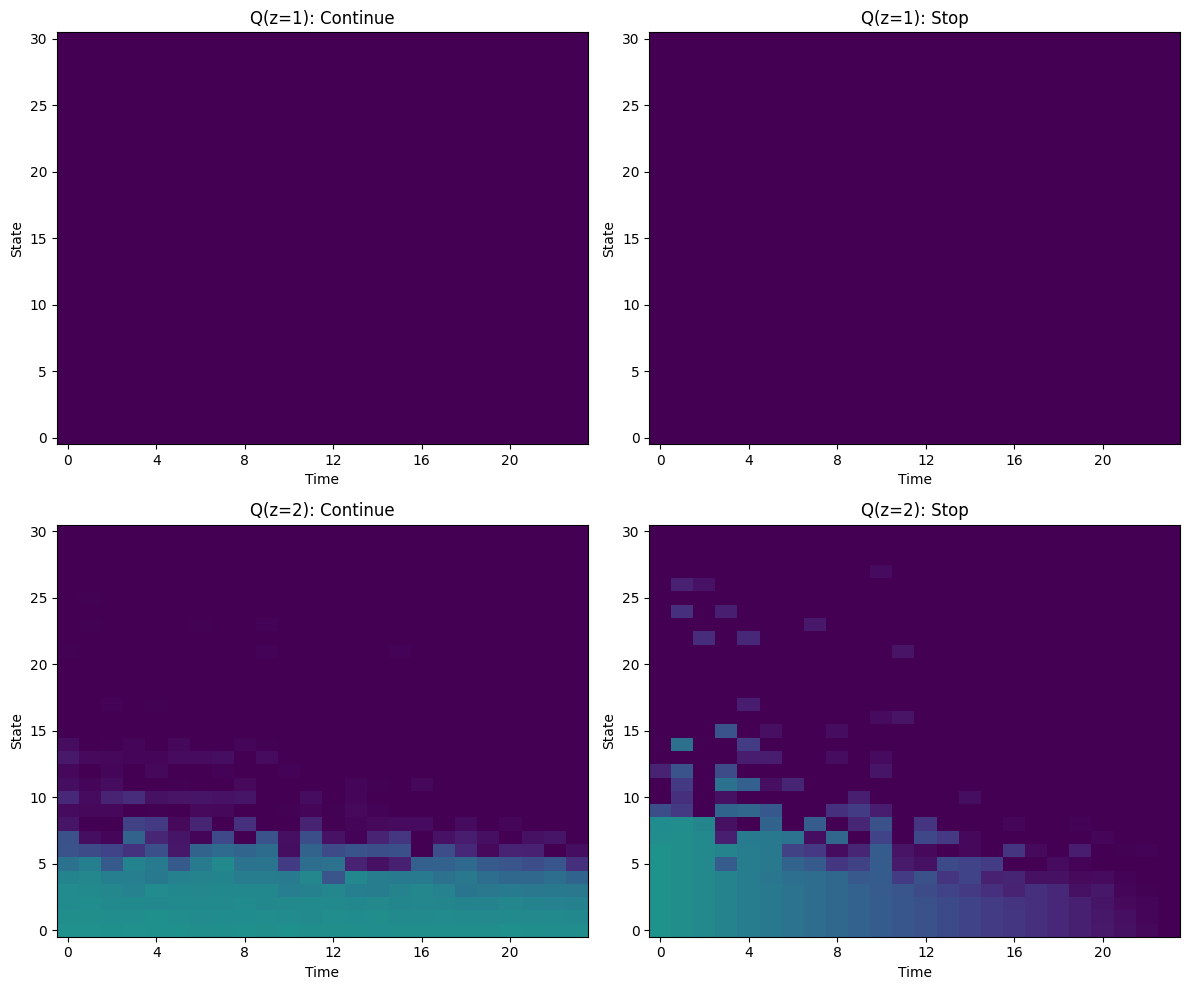

Plotting Policy...


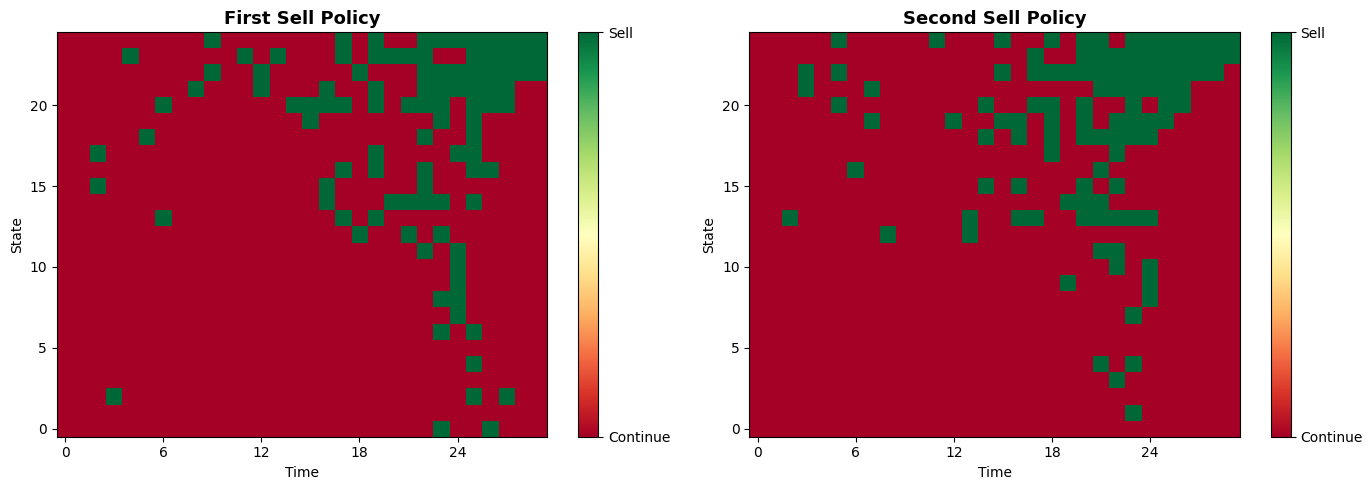


Double-Sell Policy Statistics:
 First sell rate: 13.60%
 Second sell rate: 14.27%
Plotting Training Metrics...


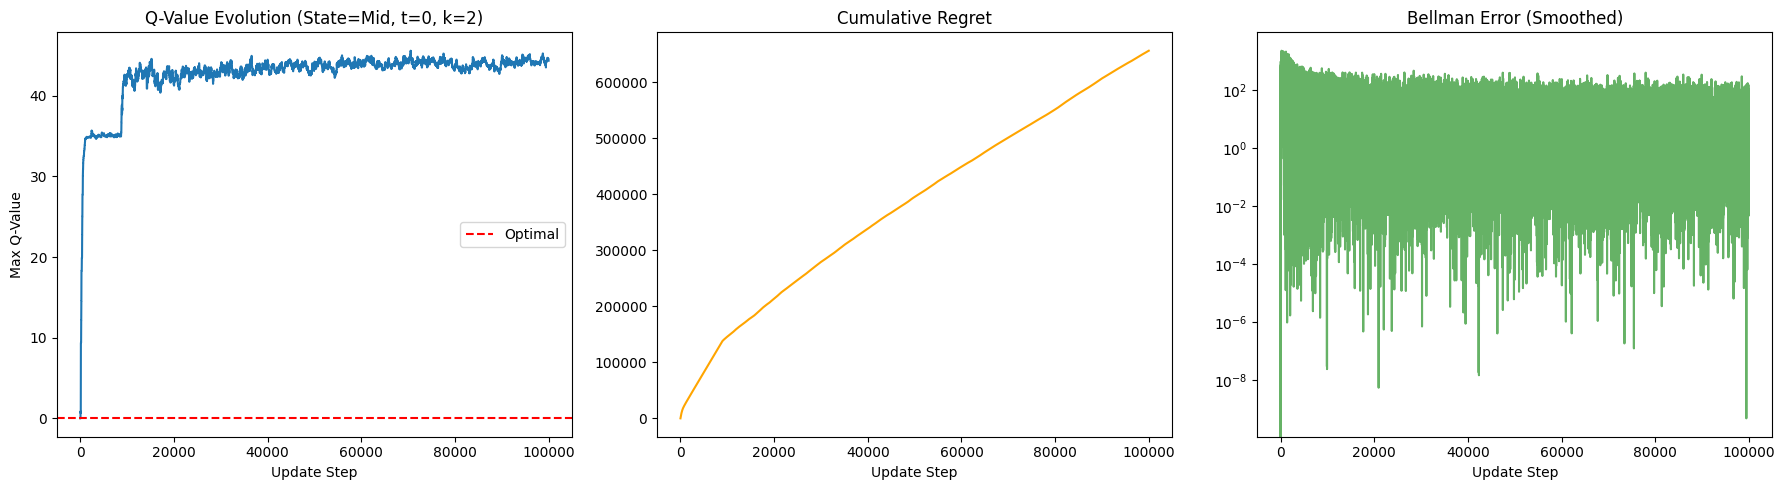

Comparing with Optimal...


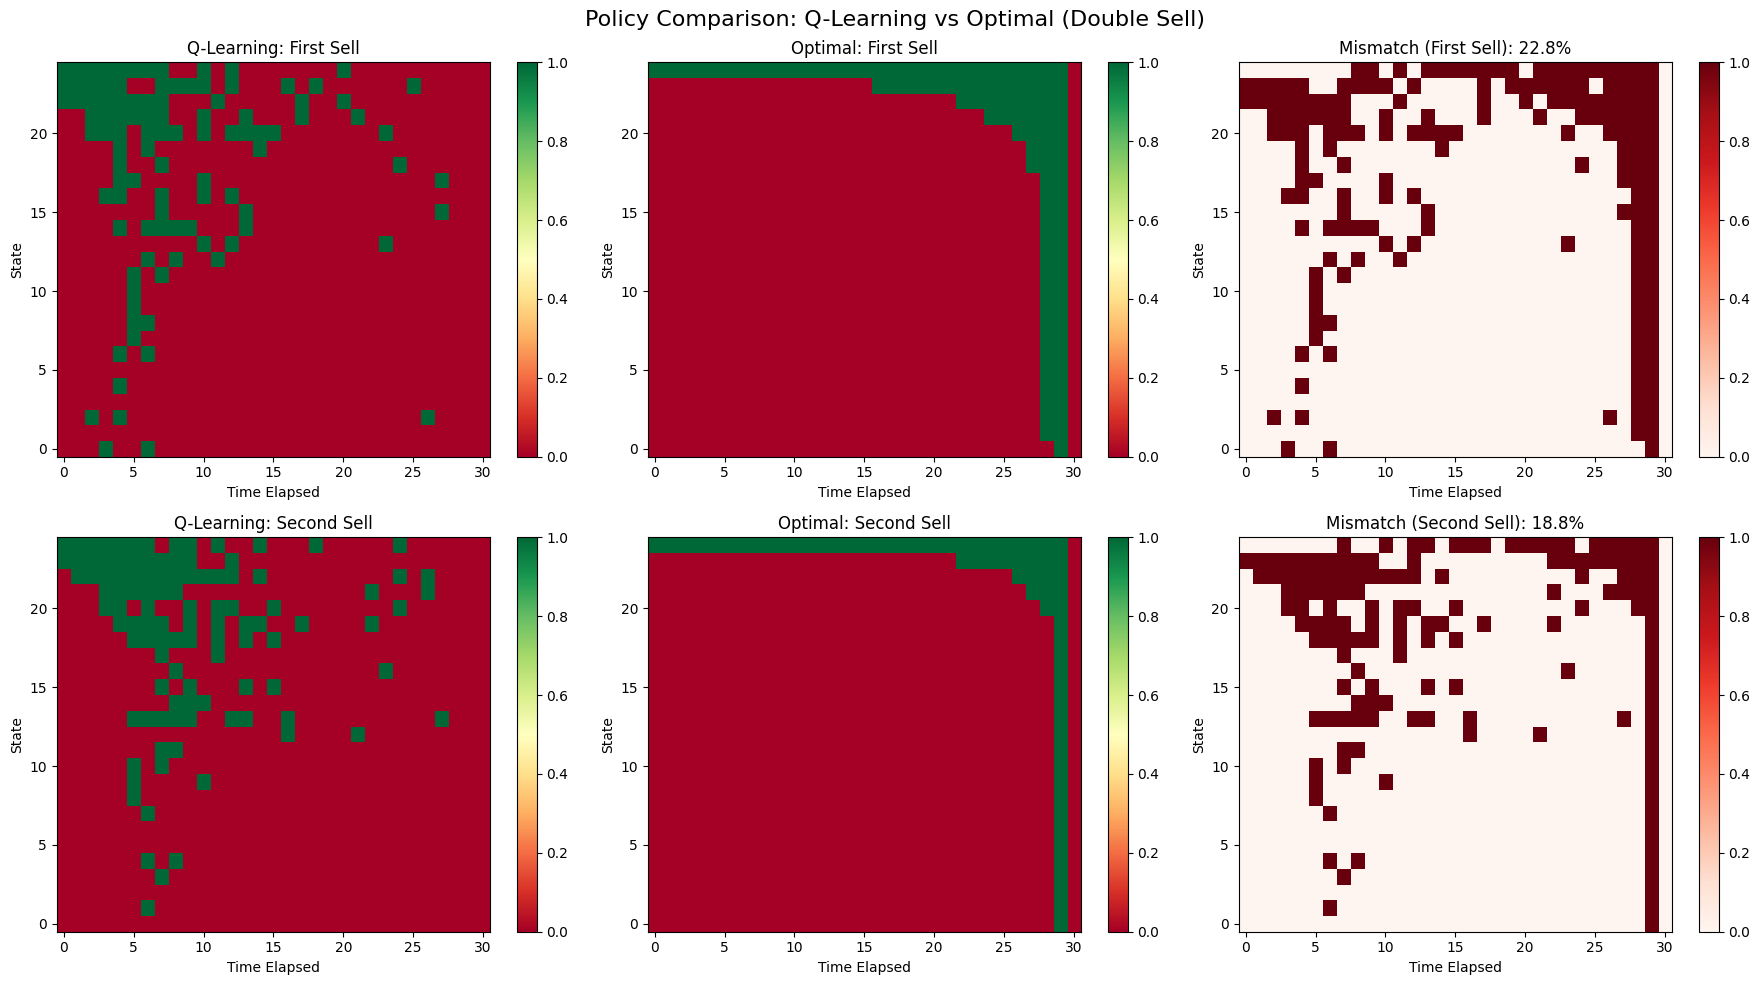


Policy Agreement Statistics (Double Sell)
First Sell Agreement: 77.2%
Second Sell Agreement: 81.2%


In [ ]:
# Assuming 'env' is initialized as DoubleSellEnv
env = DoubleSellEnv(n_states=25, max_time=30, sell_cost=0.5, transition_model='brownian', transition_params={'mu': 15, 'sigma': 10})

# # --- 1. Sequential Q-Learning ---
q_agent_1 = SequentialQLearning(env)
q_agent_1.train(episodes=100_000)
run_visualizer(env, q_agent_1, title_suffix="Sequential Q-Learning")


Training Batches: 100%|██████████| 2000/2000 [00:31<00:00, 62.87it/s]


Training Complete. Final Value Est (State 12): 49.0459

=== Running Visualizer Pipeline: LSM Agent ===
[LSM Agent] Plotting Metrics...


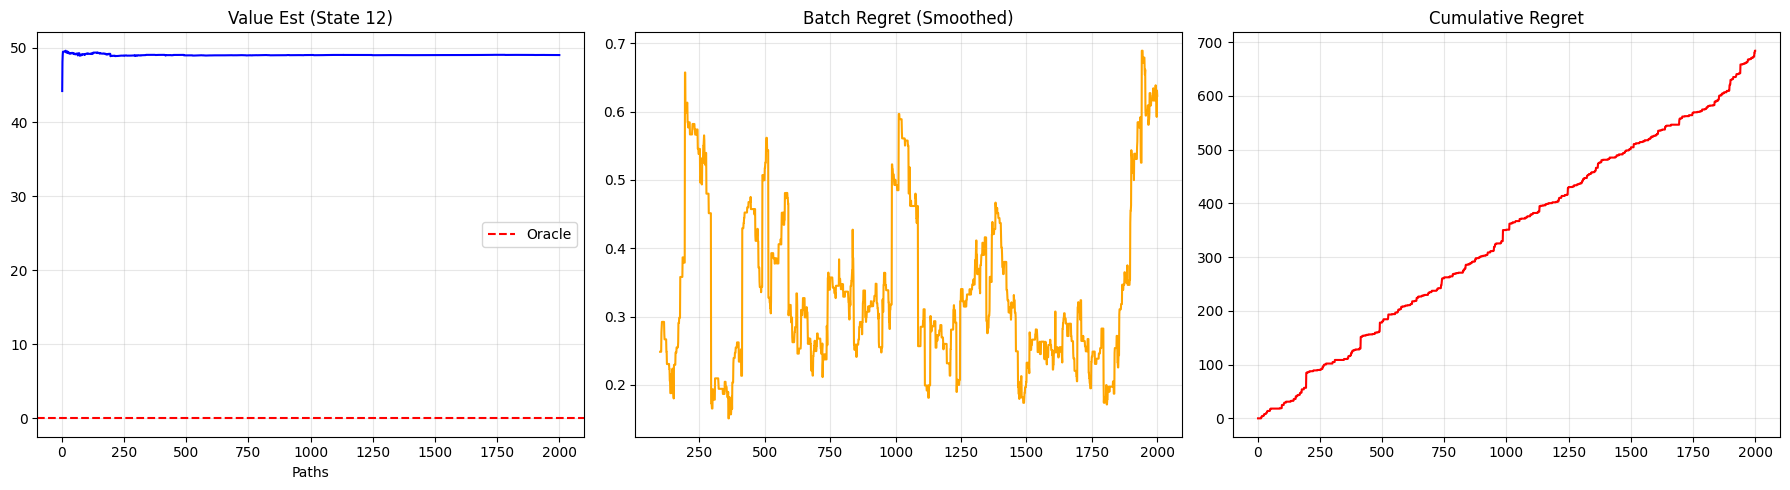

[LSM Agent] Visualizing Policy Heatmaps...


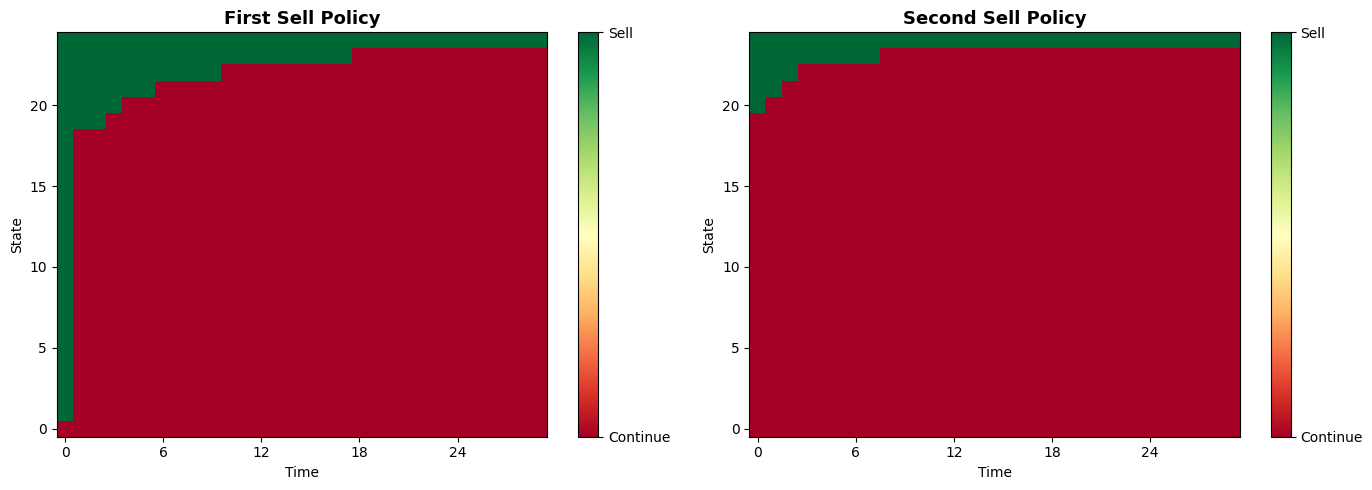


Double-Sell Policy Statistics:
 First sell rate: 11.87%
 Second sell rate: 5.87%
[LSM Agent] Visualizing Q-Table (Pseudo-Q from Regression)...


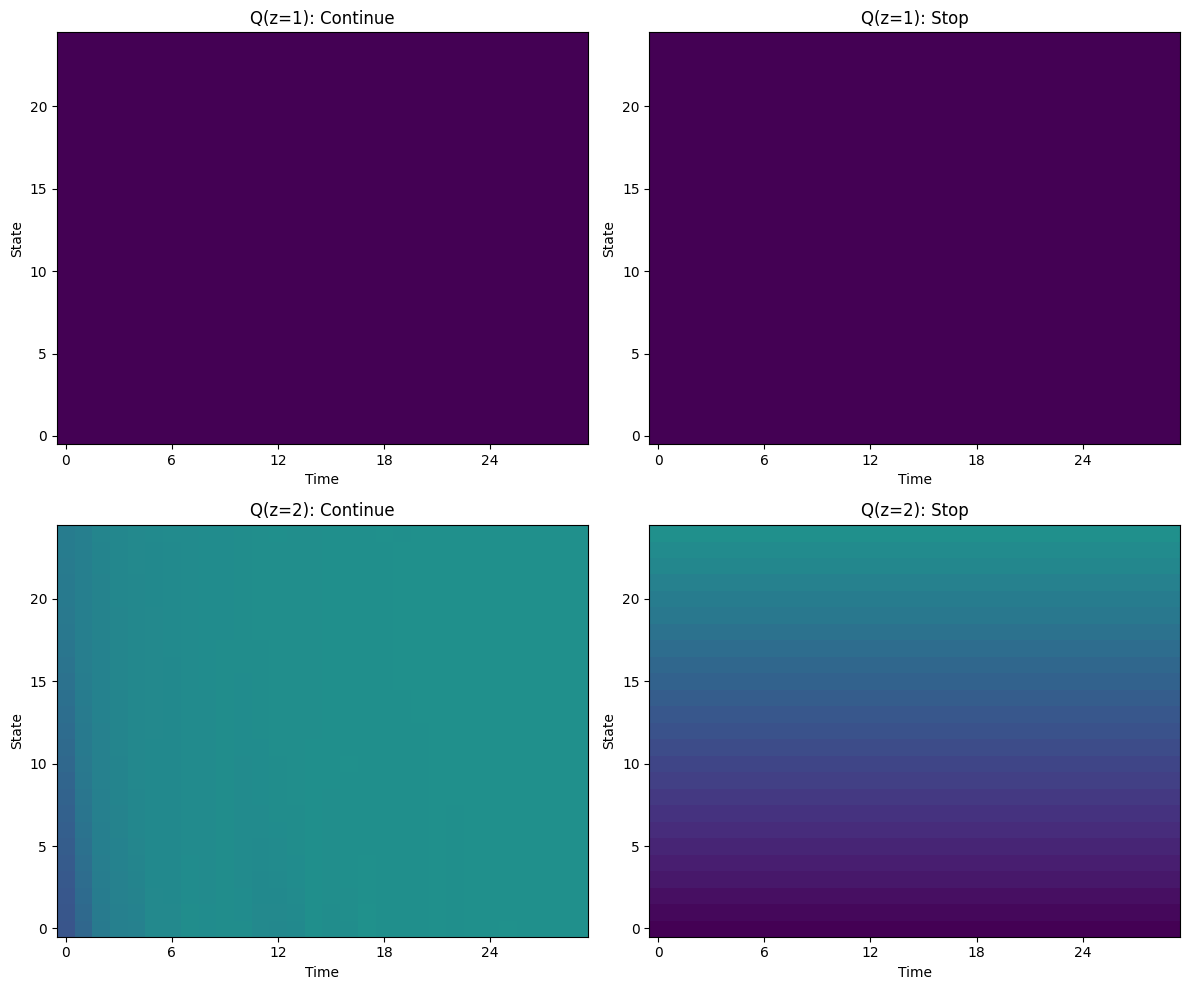

[LSM Agent] Comparing with Optimal Policy...


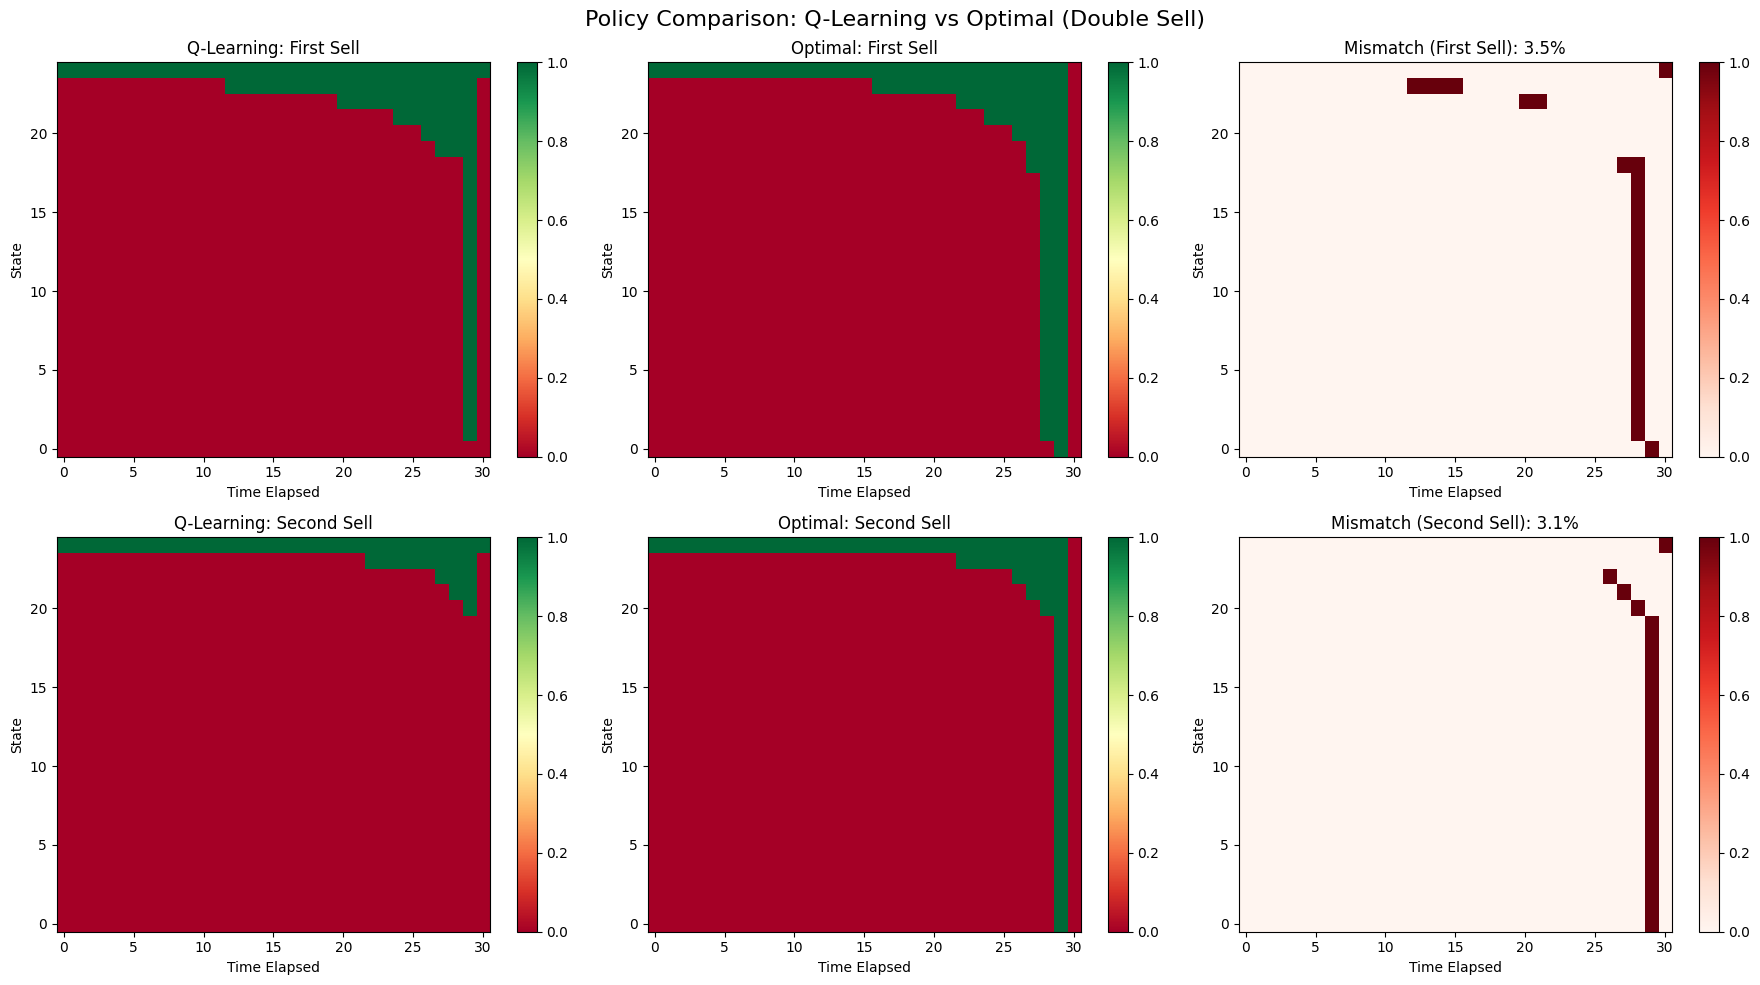


Policy Agreement Statistics (Double Sell)
First Sell Agreement: 96.5%
Second Sell Agreement: 96.9%
[LSM Agent] Pipeline Complete.



In [ ]:
agent_lsm = LSMDoubleSell(env)
agent_lsm.train(total_paths=50000, n_batches=50000)
visualizer_pipeline(env, agent_lsm, title="LSM Agent")

Training Joint Q+LSM (100 batches x 1000 paths)...


100%|██████████| 100/100 [00:38<00:00,  2.61it/s]



=== Running Visualizer Pipeline: Joint Q+LSM ===
[Joint Q+LSM] Plotting Metrics...


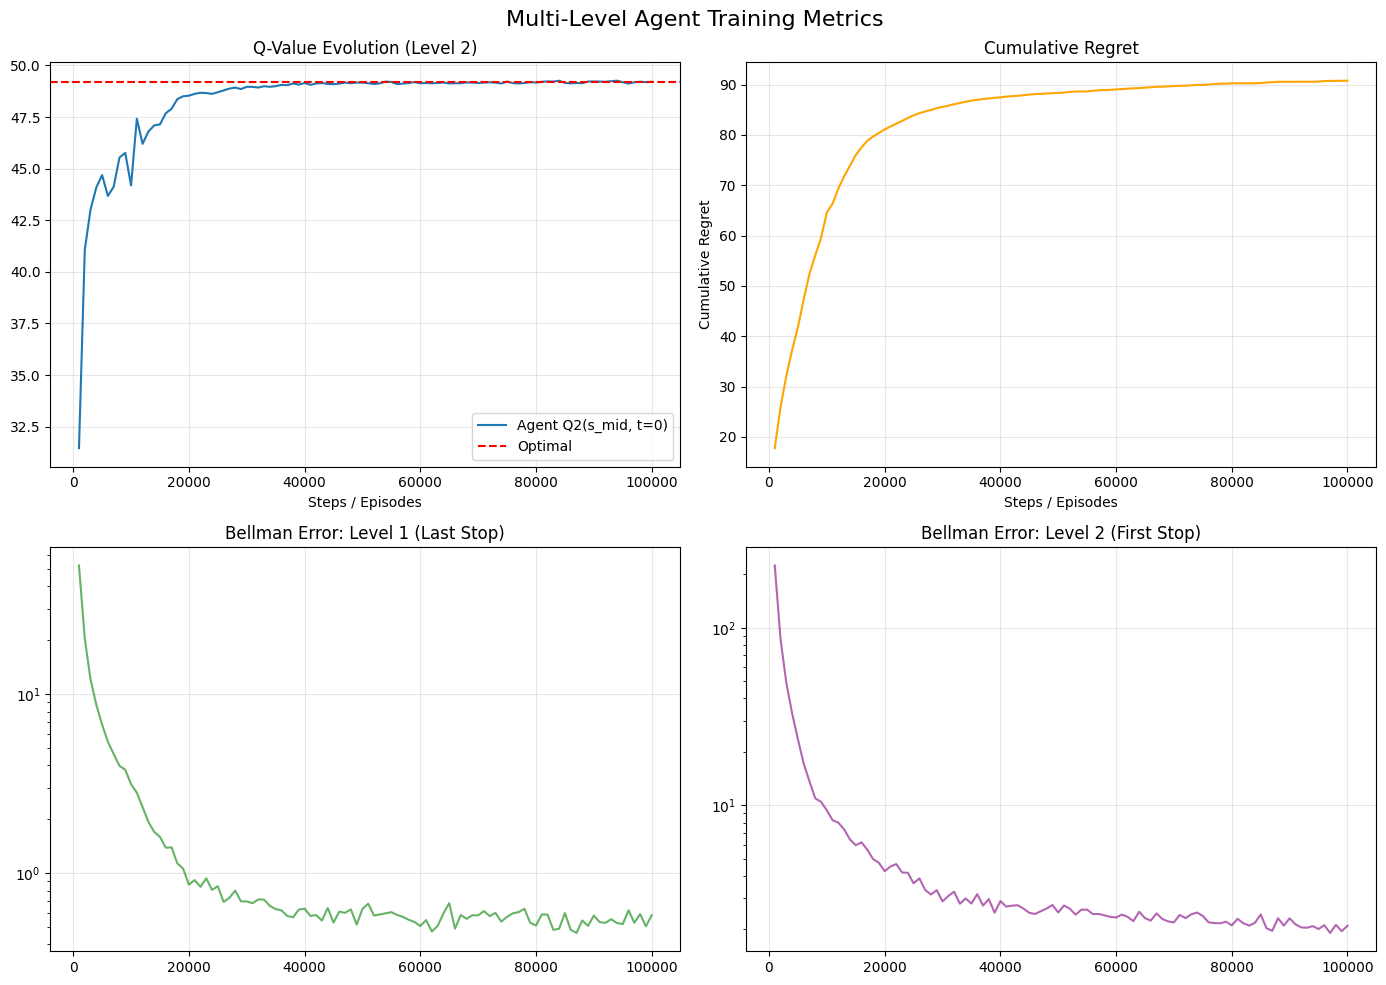

[Joint Q+LSM] Visualizing Policy Heatmaps...


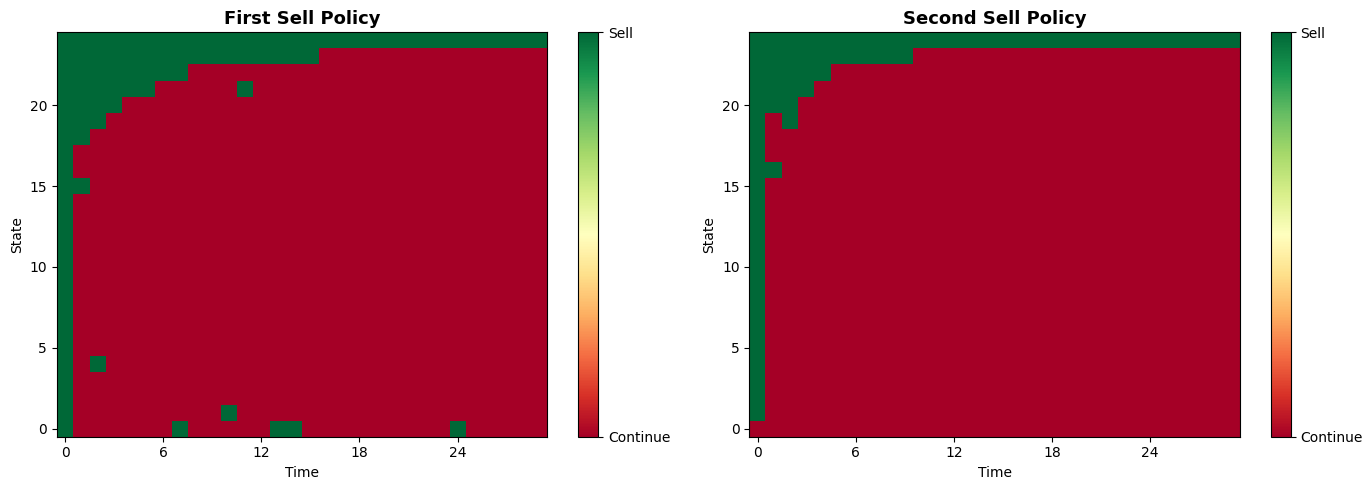


Double-Sell Policy Statistics:
 First sell rate: 12.67%
 Second sell rate: 9.73%
[Joint Q+LSM] Comparing with Optimal Policy...


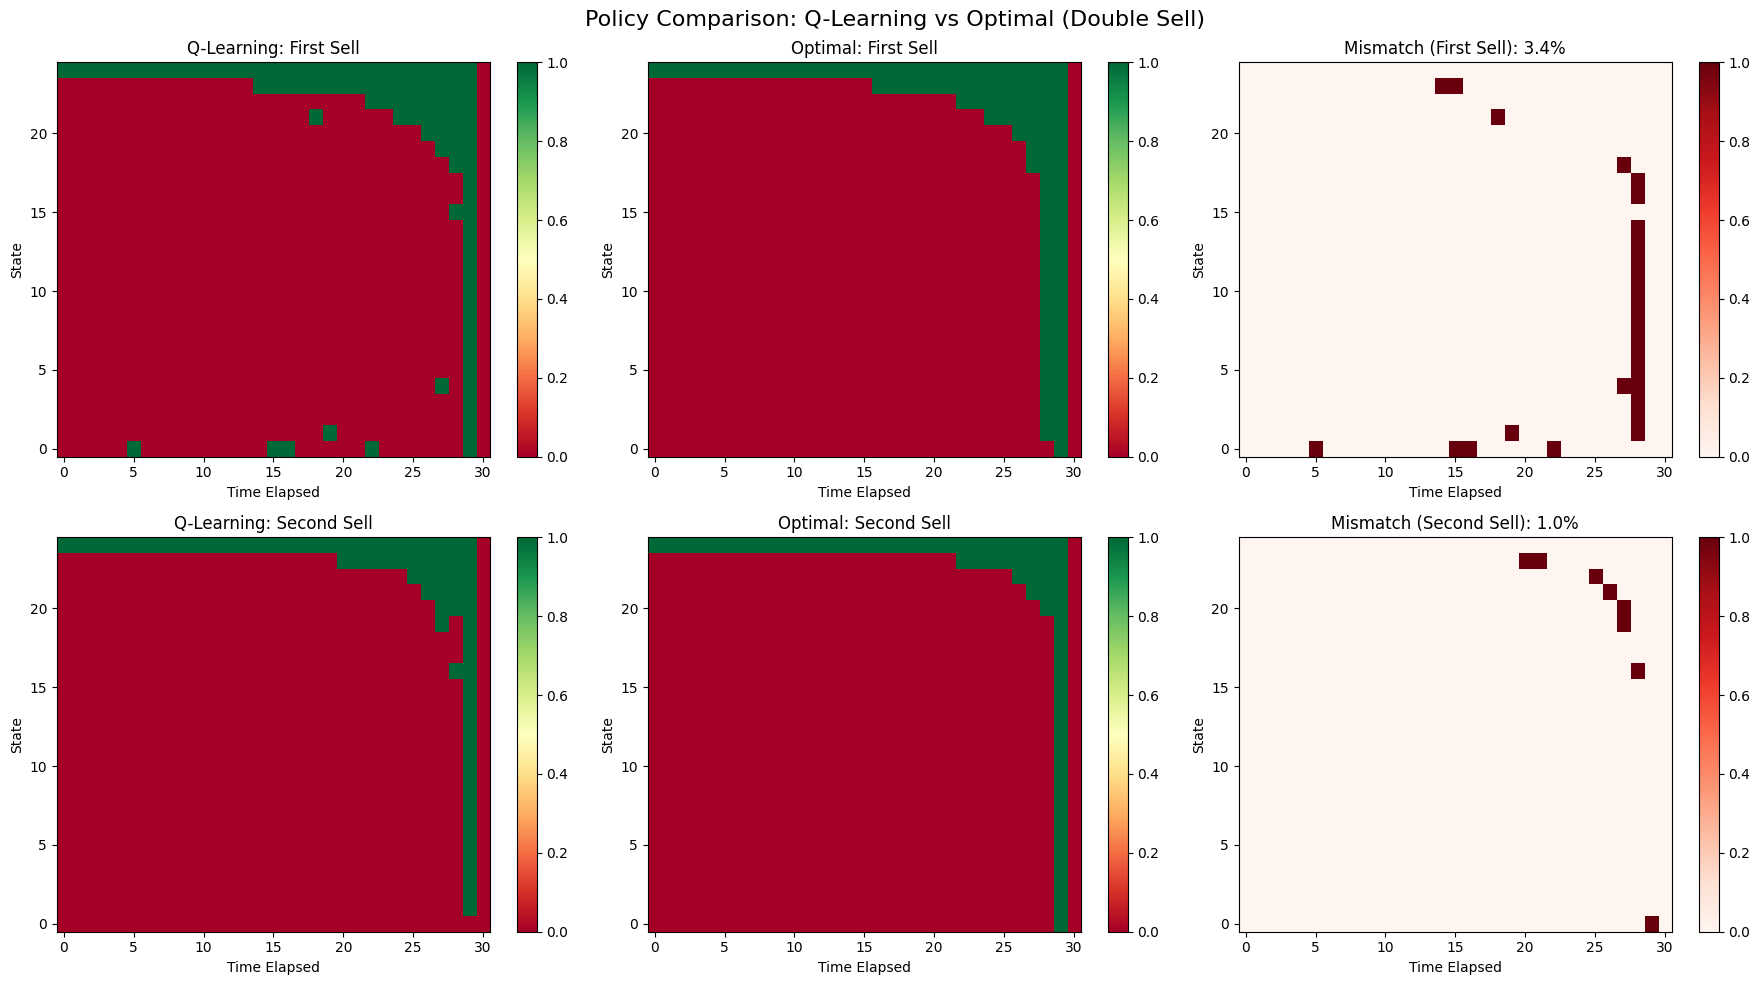


Policy Agreement Statistics (Double Sell)
First Sell Agreement: 96.6%
Second Sell Agreement: 99.0%
[Joint Q+LSM] Pipeline Complete.



In [135]:

# --- 3. Joint Training ---
lsm_params = {'poly_degree': 3, 'ridge_alpha': 1e-3}
q_agent_3 = JointMultiLevelQ_LSM(env, LSMDoubleSell_Adapted, lsm_params)
q_agent_3.train(paths_per_batch=1000, n_batches=100)
visualizer_pipeline(env, q_agent_3, "Joint Q+LSM")

Training Joint Q+LSM (50000 batches x 5 paths)...


100%|██████████| 50000/50000 [08:40<00:00, 96.00it/s] 



=== Running Visualizer Pipeline: Joint Q+LSM ===
[Joint Q+LSM] Plotting Metrics...


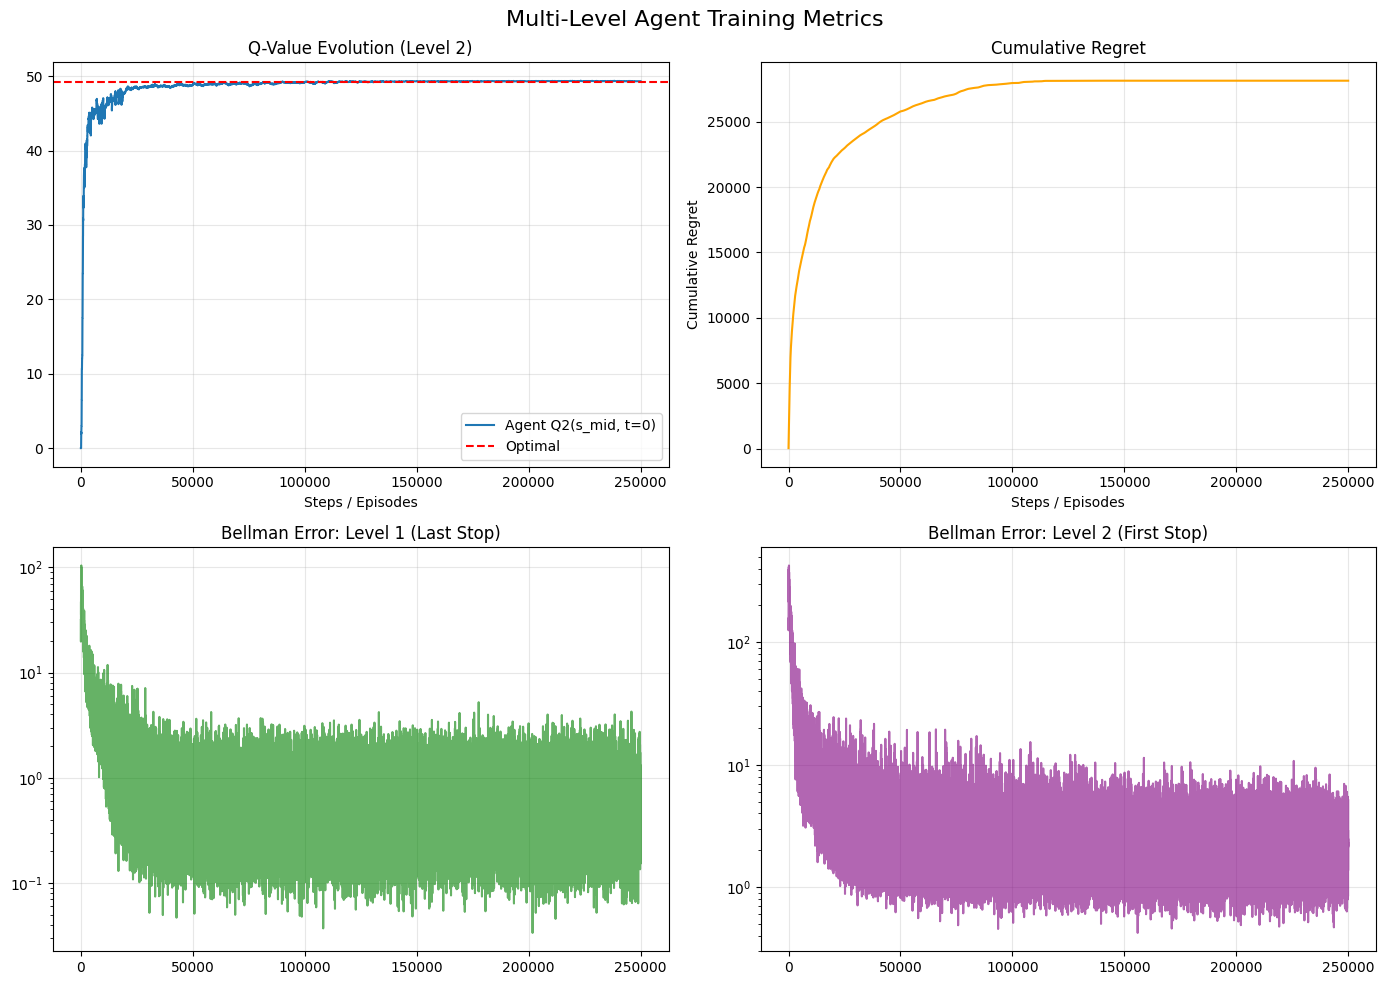

[Joint Q+LSM] Visualizing Policy Heatmaps...


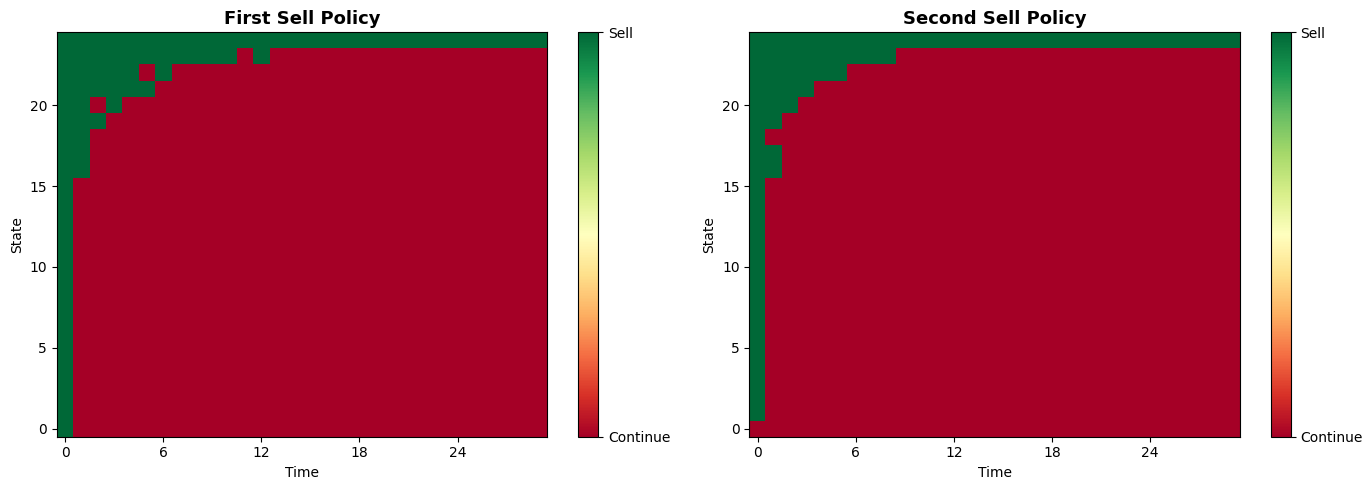


Double-Sell Policy Statistics:
 First sell rate: 10.93%
 Second sell rate: 9.87%
[Joint Q+LSM] Comparing with Optimal Policy...


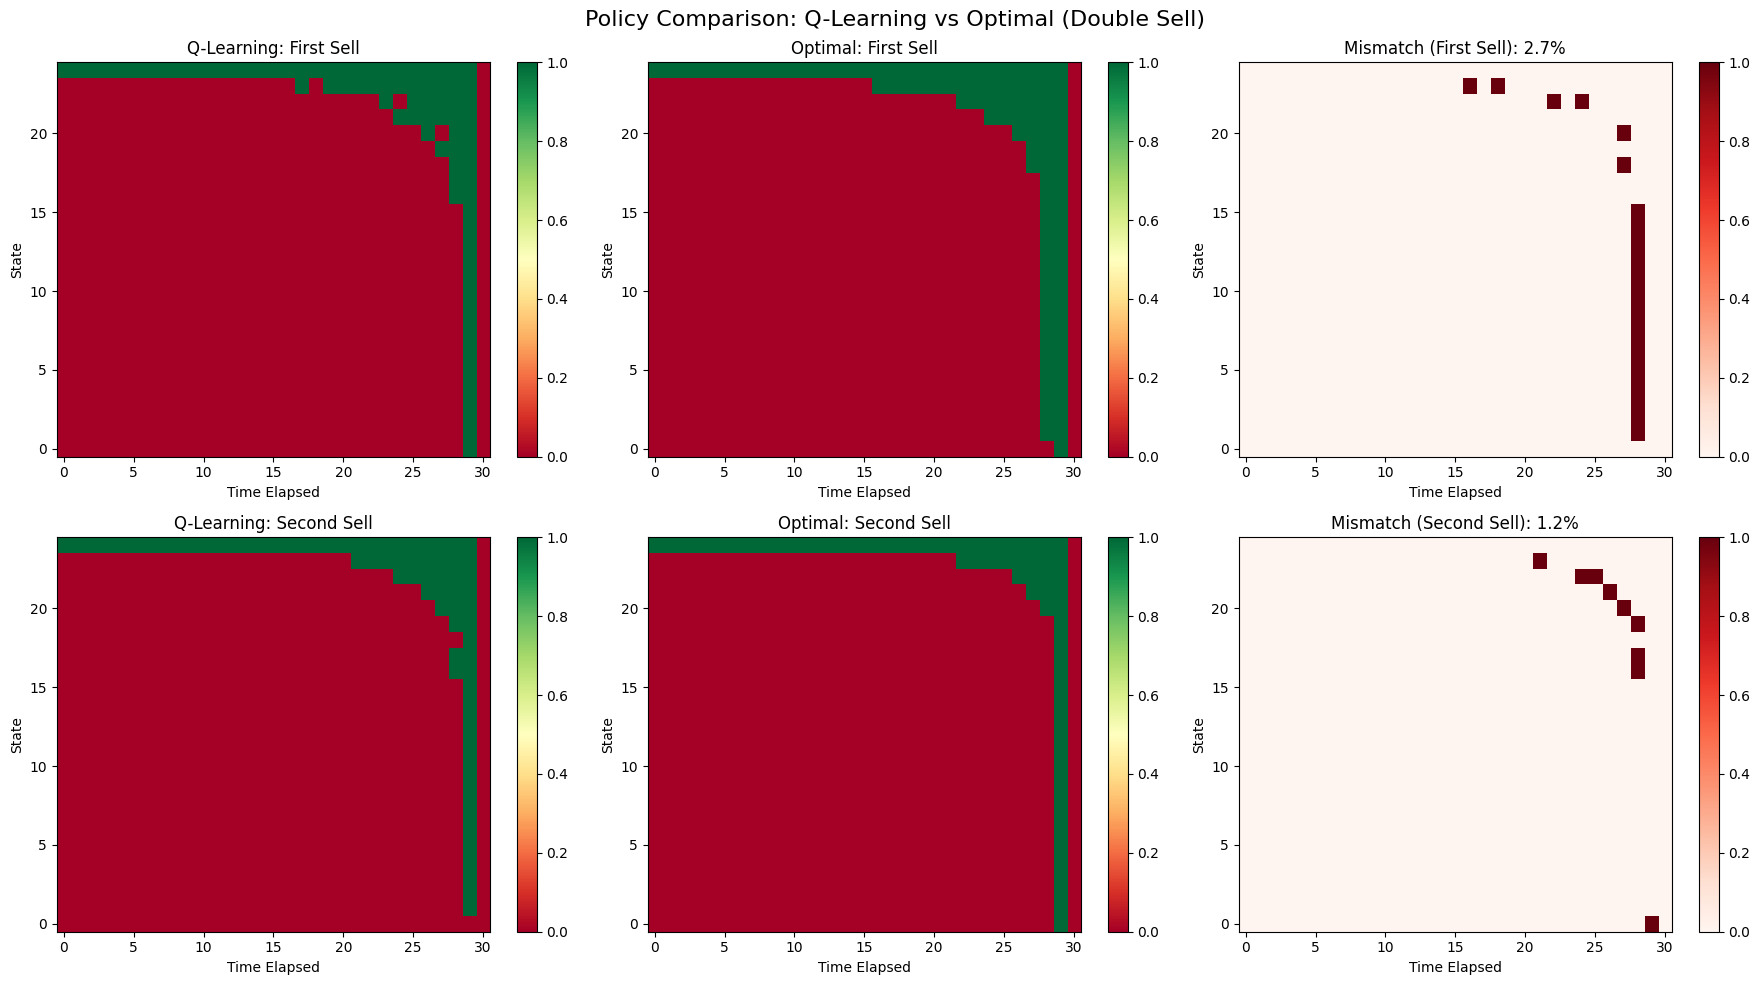


Policy Agreement Statistics (Double Sell)
First Sell Agreement: 97.3%
Second Sell Agreement: 98.8%
[Joint Q+LSM] Pipeline Complete.



In [ ]:

lsm_params = {'poly_degree': 3, 'ridge_alpha': 1e-3}
q_agent_4 = JointMultiLevelQ_LSM(env, LSMDoubleSell_Adapted, lsm_params)
q_agent_4.train(paths_per_batch=5, n_batches=50000)
visualizer_pipeline(env, q_agent_4, "Joint Q+LSM")

add 2 plots:
1. cumulative regret for q learning, q+lsm, pure lsm (include the value function evolution for each episode step)
2. value function + regret evolution for a single episode batch lsm 

>>> Initializing Environment...

>>> Training Agent 1: Pure LSM...


Training Batches:   0%|          | 0/20 [00:00<?, ?it/s]

Training Batches: 100%|██████████| 20/20 [00:09<00:00,  2.18it/s]


Training Complete. Final Value Est (State 12): 49.0613

>>> Training Agent 2: Standard Multi-Level Q...
Phase 1: Learning Last Stop (k=1)...


100%|██████████| 20000/20000 [00:00<00:00, 35141.48it/s]


Phase 2: Learning First Stop (k=2)...


... (3 outputs left out)


>>> Training Agent 4: Joint Q+LSM (B=1000)...
Training Joint Q+LSM (20 batches x 1000 paths)...


100%|██████████| 20/20 [00:07<00:00,  2.62it/s]



>>> Training Agent 5: Joint Q+LSM (B=5)...
Training Joint Q+LSM (4000 batches x 5 paths)...


100%|██████████| 4000/4000 [00:38<00:00, 103.92it/s]


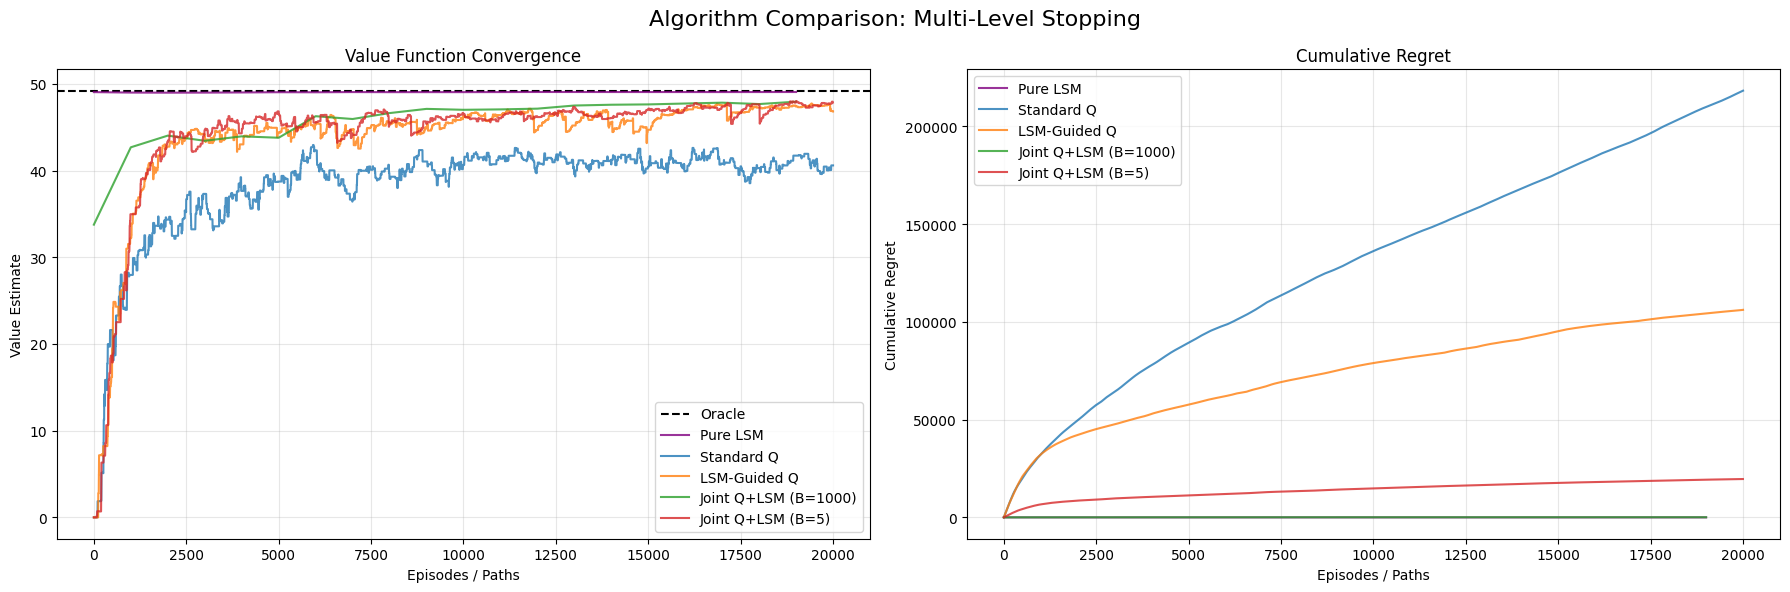

In [ ]:

def run_comprehensive_comparison():
    # 1. Setup Environment
    print(">>> Initializing Environment...")
    env = DoubleSellEnv(
        n_states=25, 
        max_time=30, 
        sell_cost=0.5, 
        transition_model='brownian', 
        transition_params={'mu': 15, 'sigma': 10}
    )

    agents = {}
    
    # --- Agent 1: Pure LSM ---
    print("\n>>> Training Agent 1: Pure LSM...")
    agent_lsm = LSMDoubleSell(env)
    agent_lsm.train(total_paths=20_000, n_batches=20)
    agents['Pure LSM'] = agent_lsm

    # --- Agent 2: Standard Q ---
    print("\n>>> Training Agent 2: Standard Multi-Level Q...")
    agent_std = SequentialQLearning(env, learning_rate=0.1)
    agent_std.train(episodes=20_000) 
    agents['Standard Q'] = agent_std

    # --- Agent 3: Joint LSM-Q (B=1000) ---
    print("\n>>> Training Agent 3: Joint Q+LSM (B=1000)...")
    lsm_params = {'poly_degree': 3, 'ridge_alpha': 1e-3}
    agent_joint_1k = JointMultiLevelQ_LSM(env, LSMDoubleSell_Adapted, lsm_params, lr=0.1)
    agent_joint_1k.train(paths_per_batch=1000, n_batches=20) # 20k total
    agents['Joint Q+LSM (B=1000)'] = agent_joint_1k

    # --- Agent 4: Joint LSM-Q (B=5) ---
    print("\n>>> Training Agent 4: Joint Q+LSM (B=5)...")
    agent_joint_5 = JointMultiLevelQ_LSM(env, LSMDoubleSell_Adapted, lsm_params, lr=0.1)
    agent_joint_5.train(paths_per_batch=5, n_batches=4000) # 20k total
    agents['Joint Q+LSM (B=5)'] = agent_joint_5

    # ---------------------------------------------------------
    # Visualization
    # ---------------------------------------------------------
    plot_combined_results(agents, env)

def plot_combined_results(agents, env):
    fig, axs = plt.subplots(1, 2, figsize=(18, 6))
    fig.suptitle('Algorithm Comparison: Multi-Level Stopping', fontsize=16)
    colors = ['purple', '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
    
    # Oracle Value (at Start: Time Remaining = T)
    try:
        V_opt, _ = env.solve_optimal_policy(verbose=False)
        oracle_val = V_opt[env.n_states // 2, env.max_time, 2]
        axs[0].axhline(oracle_val, color='k', linestyle='--', label='Oracle', linewidth=1.5)
    except:
        pass

    for i, (name, agent) in enumerate(agents.items()):
        color = colors[i % len(colors)]
        
        # Extract Value History
        if hasattr(agent, 'history'):
            if 'value_evolution' in agent.history: vals = agent.history['value_evolution'] # LSM
            elif 'q2_value_evolution' in agent.history: vals = agent.history['q2_value_evolution'] # Joint/Guided
            elif 'q_values' in agent.history: vals = agent.history['q_values'] # Std Q
            else: vals = []
            
            # Extract Regret History
            if 'cumulative_regret' in agent.history:
                regrets = agent.history['cumulative_regret']
            elif 'cum_regret' in agent.history:
                regrets = agent.history['cum_regret']
            else:
                regrets = []

            # Normalize X-axis to "Episodes/Paths"
            steps = np.arange(len(vals))
            if "Pure LSM" in name: steps = steps * (20000 // len(vals))
            elif "B=1000" in name: steps = steps * 1000
            elif "B=5" in name: steps = steps * 5
            # Guided/Std usually 1 per episode
            
            if len(vals) > 0:
                axs[0].plot(steps, vals, label=name, color=color, alpha=0.8)
            if len(regrets) > 0:
                axs[1].plot(steps, regrets, label=name, color=color, alpha=0.8)

    axs[0].set_title('Value Function Convergence')
    axs[0].set_xlabel('Episodes / Paths')
    axs[0].set_ylabel('Value Estimate')
    axs[0].legend()
    axs[0].grid(True, alpha=0.3)

    axs[1].set_title('Cumulative Regret')
    axs[1].set_xlabel('Episodes / Paths')
    axs[1].set_ylabel('Cumulative Regret')
    axs[1].legend()
    axs[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    run_comprehensive_comparison()

>>> Initializing Environment...

>>> Training Agent 1: Pure LSM...


100%|██████████| 20/20 [01:31<00:00,  4.58s/it]



>>> Training Agent 2: LSM-Guided Q...
Pre-fetching LSM values for guidance...


  0%|          | 0/20 [00:00<?, ?it/s]

Training LSM-Guided Multi-Level Q...


  5%|▌         | 1/20 [00:00<00:13,  1.40it/s]

... (76 outputs left out)

Training Joint Q+LSM (1 batches x 1000 paths)...


 95%|█████████▌| 19/20 [00:08<00:00,  2.11it/s]

Training Joint Q+LSM (1 batches x 1000 paths)...


100%|██████████| 20/20 [00:09<00:00,  2.13it/s]


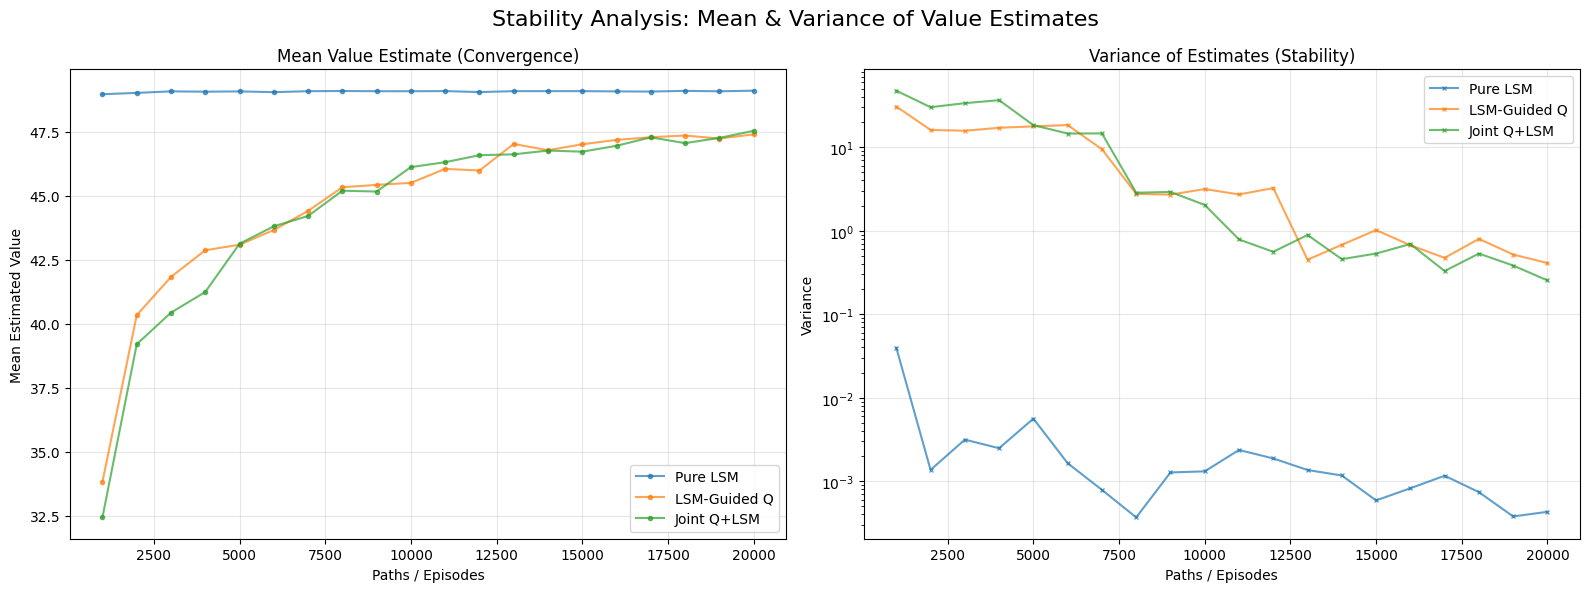


=== Final Test Set Statistics (N=1000 States) ===
Agent                | Mean Value   | Variance    
--------------------------------------------------
Pure LSM             |    49.0995   |     0.0003
LSM-Guided Q         |    47.3939   |     0.4055
Joint Q+LSM          |    47.5319   |     0.2503


In [ ]:

def evaluate_agent_value_stats(agent, env, n_test_states=500):
    """
    Computes the Mean and Variance of the agent's Value Estimate V_0(s)
    across a fixed distribution of starting states.
    """
    # Fix a set of states to evaluate stability
    # We use a linspace of states to cover the whole grid
    test_states = np.linspace(0, env.n_states-1, n_test_states).astype(int)
    
    values = []
    
    # Extract V_0(s) depending on Agent Type
    if hasattr(agent, 'get_value_estimate'):
        # LSM-based agents (Pure LSM, Joint LSM) have this method
        # V_est shape: (S, T+1, K+1)
        V_table = agent.get_value_estimate()
        # We want V at t=0 for k=2 (First Sell)
        values = V_table[test_states, 0, 2]
        
    elif hasattr(agent, 'Q'):
        # Q-Learning agents (Standard Q, Guided Q)
        # Q shape: (S, T+1, K+1, Action) -> Take max over actions
        for s in test_states:
            val = np.max(agent.Q[s, 0, 2, :])
            values.append(val)
        values = np.array(values)
        
    elif hasattr(agent, 'Q2'):
        # MultiLevel agents (older structure if strictly following base class)
        for s in test_states:
            val = np.max(agent.Q2[s, 0, :])
            values.append(val)
        values = np.array(values)
        
    return np.mean(values), np.var(values)

# --- Updated Run Function ---
def run_comprehensive_comparison_with_stats():
    print(">>> Initializing Environment...")
    env = DoubleSellEnv(
        n_states=25, 
        max_time=30, 
        sell_cost=0.5, 
        transition_model='brownian', 
        transition_params={'mu': 15, 'sigma': 10}
    )

    agents = {}
    stats_history = {} # Store (step, mean, var) tuples

    # --- 1. Pure LSM ---
    print("\n>>> Training Agent 1: Pure LSM...")
    agent_lsm = LSMDoubleSell(env)
    # Custom training loop to track stats
    stats_lsm = []
    total_paths = 20_000
    n_batches = 20
    paths_per_batch = total_paths // n_batches
    
    for b in tqdm(range(n_batches)):
        # Train on one batch (using the adapted method if available, or incremental)
        # Note: Standard LSM usually retrains from scratch. 
        # For fair comparison, we train incrementally or just re-run full train
        # Here we simulate incremental by just running train on growing subset
        current_paths = (b + 1) * paths_per_batch
        agent_lsm.train(total_paths=current_paths, n_batches=b+1, verbose=False)
        
        mu, var = evaluate_agent_value_stats(agent_lsm, env)
        stats_lsm.append((current_paths, mu, var))
        
    agents['Pure LSM'] = agent_lsm
    stats_history['Pure LSM'] = stats_lsm

    # --- 3. Joint LSM-Q (B=1000) ---
    print("\n>>> Training Agent 3: Joint Q+LSM (B=1000)...")
    lsm_params = {'poly_degree': 3, 'ridge_alpha': 1e-3}
    agent_joint = JointMultiLevelQ_LSM(env, LSMDoubleSell_Adapted, lsm_params, lr=0.1)
    stats_joint = []
    total_paths = 20_000
    batch_size = 1000
    n_batches = total_paths // batch_size
    
    for b in tqdm(range(n_batches)):
        agent_joint.train(paths_per_batch=batch_size, n_batches=1)
        mu, var = evaluate_agent_value_stats(agent_joint, env)
        current_paths = (b+1) * batch_size
        stats_joint.append((current_paths, mu, var))
        
    agents['Joint Q+LSM'] = agent_joint
    stats_history['Joint Q+LSM'] = stats_joint

    # ---------------------------------------------------------
    # Visualization
    # ---------------------------------------------------------
    plot_variance_comparison(stats_history)
    print_final_stats(agents, env)

def plot_variance_comparison(stats_history):
    fig, axs = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle('Stability Analysis: Mean & Variance of Value Estimates', fontsize=16)
    
    for name, stats in stats_history.items():
        steps, means, vars = zip(*stats)
        
        # Plot Mean Convergence
        axs[0].plot(steps, means, label=name, marker='o', markersize=3, alpha=0.7)
        
        # Plot Variance (Stability)
        axs[1].plot(steps, vars, label=name, marker='x', markersize=3, alpha=0.7)

    axs[0].set_title("Mean Value Estimate (Convergence)")
    axs[0].set_xlabel("Paths / Episodes")
    axs[0].set_ylabel("Mean Estimated Value")
    axs[0].legend()
    axs[0].grid(True, alpha=0.3)

    axs[1].set_title("Variance of Estimates (Stability)")
    axs[1].set_xlabel("Paths / Episodes")
    axs[1].set_ylabel("Variance")
    axs[1].legend()
    axs[1].grid(True, alpha=0.3)
    axs[1].set_yscale('log') # Log scale often helps visualize variance reduction

    plt.tight_layout()
    plt.show()

def print_final_stats(agents, env):
    print("\n=== Final Test Set Statistics (N=1000 States) ===")
    print(f"{'Agent':<20} | {'Mean Value':<12} | {'Variance':<12}")
    print("-" * 50)
    
    for name, agent in agents.items():
        mu, var = evaluate_agent_value_stats(agent, env, n_test_states=1000)
        print(f"{name:<20} | {mu:10.4f}   | {var:10.4f}")

if __name__ == "__main__":
    run_comprehensive_comparison_with_stats()